In [1]:
# https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews
import pandas as pd
import matplotlib.pyplot as plt

reviews_path = '/Users/colinwenzel/Desktop/CSE 3521 Project/group_sample_seed48.csv'

df = pd.read_csv(reviews_path)
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,515539,B001U8CED2,A38XS08I7CNOUY,nncym,3,4,1,1300060800,Nasty Stuff - Cats Hate It!,I am owned by 5 cats and I foster another 17 c...
1,318059,B0024NKMEU,A1W1TQI2UZDY4R,Charles Baker,1,1,5,1269475200,Jerky spice,"This pack was exceptional for a ""newbie"" jerky..."
2,34626,B000GQTP1S,A1DRP529AHD8F1,"Ralph Kuser ""seeking intelligent life""",1,2,5,1302393600,Nice and hot!,These chips are just hot enough to make them i...
3,131230,B00004RAMX,A275XT9A7OV1PL,wayfarer,0,0,1,1318550400,Junky gopher trap,This trap is very poor quality. Lock bar was t...
4,312766,B003KJ0DDC,A18QI1MZI0L8KB,"L. Arters ""living with MS""",0,0,5,1349827200,Delicious,I love these whole wheat crackers by Lance! I...


In [2]:
# Dataset Summary

number_of_reviews = len(df)
print("Number of reviews:", number_of_reviews)

# Count the words in each review
review_text = df["Text"].fillna("")
review_words = review_text.str.split()
word_counts = review_words.str.len()

average_length = word_counts.mean()
print("Average review length:", round(average_length, 2), "words")

# Count missing values in each column
print("Missing values:")
print(df.isna().sum())

# Count completely identical rows
identical_rows = df.duplicated().sum()
print("Identical rows:", identical_rows)

# Count duplicate review text
# Every row has a unique Id, so whole-row duplicates will always be 0.
# The same review is often posted under several product variants
# (same user, same score, same text, different ProductId), so check the text itself.
duplicate_text = df.duplicated(subset=["Text"]).sum()
repeated_reviews = df[df.duplicated(subset=["Text"], keep=False)]["Text"].nunique()
print("Duplicate review texts:", duplicate_text)
print("Reviews repeated more than once:", repeated_reviews)

Number of reviews: 50000


Average review length: 79.93 words
Missing values:
Id                        0
ProductId                 0
UserId                    0
ProfileName               1
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score                     0
Time                      0
Summary                   2
Text                      0
dtype: int64
Identical rows: 0
Duplicate review texts: 3738
Reviews repeated more than once: 3091


In [3]:
# Clean the data
# 1) Remove the 2 rows with a missing summary
# 2) Remove duplicate review text (same review posted under multiple product variants),
#    keeping the first copy, so the same review can't end up in both train and test
clean_df = df.dropna(subset=["Summary"]).copy()
print("Rows after removing missing summaries:", len(clean_df))

clean_df = clean_df.drop_duplicates(subset=["Text"]).copy()
print("Rows after removing duplicate reviews:", len(clean_df))

print("Rows after cleaning:", len(clean_df))

Rows after removing missing summaries: 49998
Rows after removing duplicate reviews: 46261
Rows after cleaning: 46261


In [4]:
# Dataset Summary

# Convert star ratings into three sentiment groups
sentiment_map = {
    1: "Negative",
    2: "Negative",
    3: "Neutral",
    4: "Positive",
    5: "Positive"
}

clean_df["Sentiment"] = clean_df["Score"].map(sentiment_map)

counts = clean_df["Sentiment"].value_counts().reindex(["Negative", "Neutral", "Positive"])

sentiment_table = counts.to_frame(name="Count")
sentiment_table["Percentage"] = (counts / len(clean_df) * 100)

display(sentiment_table)

,Count,Percentage
Sentiment,,
Negative,6653,14.381444
Neutral,3543,7.658719
Positive,36065,77.959837


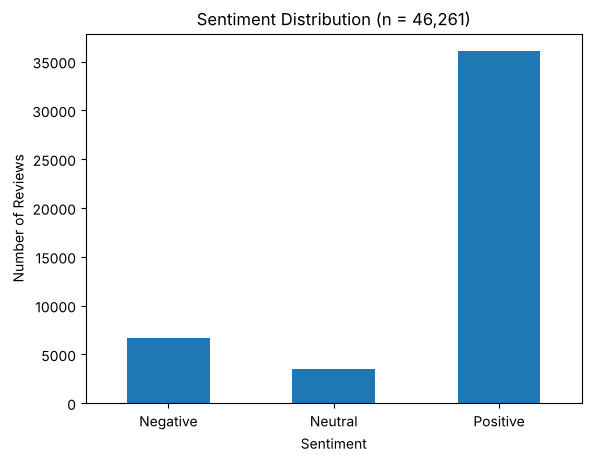

In [5]:
# Dataset Summary

counts.plot(kind="bar", rot=0)

plt.title(f"Sentiment Distribution (n = {len(clean_df):,})")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [6]:
# clean_df is the final cleaned dataset used for modeling (46,261 reviews).
# Split into train/test (80/20, seed 48) in Milestone 2.
model_df = clean_df
print("Reviews ready for modeling:", len(model_df))

Reviews ready for modeling: 46261
